In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer

# Level A — Easy

## A1. Data Types & Attributes

In [30]:
df = pd.read_csv('Penguin_Species_Prediction_Dataset.csv')
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,41.1,18.4,195.0,3886.0,Female
1,Gentoo,Biscoe,50.0,15.4,217.0,4303.0,Male
2,Gentoo,Biscoe,50.0,15.1,220.0,4954.0,Female
3,Chinstrap,Dream,48.7,19.0,196.0,3739.0,Male
4,Adelie,Dream,39.0,17.8,187.0,3607.0,Male


In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            1000 non-null   str    
 1   island             1000 non-null   str    
 2   culmen_length_mm   990 non-null    float64
 3   culmen_depth_mm    990 non-null    float64
 4   flipper_length_mm  990 non-null    float64
 5   body_mass_g        990 non-null    float64
 6   sex                990 non-null    str    
dtypes: float64(4), str(3)
memory usage: 54.8 KB


1. **`species` (Nominal):** Categorical variable representing the species of the penguin (Adelie, Chinstrap, Gentoo).
2. **`island` (Nominal):** Categorical variable indicating the island where the observation took place (Torgersen, Biscoe, Dream).
3. **`sex` (Nominal):** Binary categorical variable indicating the biological sex (Male, Female).
4. **`culmen_length_mm` (Continuous):** Numeric measurement of the culmen length in millimeters.
5. **`culmen_depth_mm` (Continuous):** Numeric measurement of the culmen depth in millimeters.
6. **`flipper_length_mm` (Continuous):** Measurement of flipper length in millimeters. 
7. **`body_mass_g` (Continuous):** Measurement of body mass in grams.

In [32]:
numeric_cols = df.select_dtypes(include=[np.number]).columns

stats = {}

for col in numeric_cols:
    s = df[col].dropna()
    mean_val = s.mean()
    median_val = s.median()
    mode_val = s.mode()[0]
    ptp_range = s.max() - s.min()
    var_val = s.var()
    std_val = s.std()
    q25, q75 = s.quantile(0.25), s.quantile(0.75)
    iqr_val = q75 - q25
    
    stats[col] = {
        'Mean': mean_val,
        'Median': median_val,
        'Mode': mode_val,
        'Range': ptp_range,
        'Variance': var_val,
        'Std Dev': std_val,
        'IQR': iqr_val
    }

stats_df = pd.DataFrame(stats)
stats_df.round(2)

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
Mean,43.82,17.34,199.22,4103.31
Median,43.80,17.80,195.00,3882.00
Mode,38.30,18.20,189.00,3318.00
Range,23.60,8.40,60.00,3487.00
Variance,28.20,3.17,173.49,497497.17
Std Dev,5.31,1.78,13.17,705.33
IQR,9.30,2.90,23.00,1001.00


1. **`culmen_length_mm`:**
   - **Central Tendency:** The mean ($43.82\text{ mm}$) and median ($43.80\text{ mm}$) are practically identical, indicating a balanced, symmetric distribution.
   - **Dispersion:** Standard deviation is $5.31\text{ mm}$ with an $\text{IQR}$ of $9.30\text{ mm}$, showing moderate variability across different penguin species.

2. **`culmen_depth_mm`:**
   - **Central Tendency:** Mean ($17.34\text{ mm}$) is slightly lower than the median ($17.80\text{ mm}$), suggesting a mild left skewness due to Gentoo penguins having shallower culmens.
   - **Dispersion:** Shows the lowest variability among all features ($\text{Std Dev} = 1.78\text{ mm}$, $\text{IQR} = 2.90\text{ mm}$).

3. **`flipper_length_mm`:**
   - **Central Tendency:** Mean ($199.22\text{ mm}$) is higher than the median ($195.00\text{ mm}$), showing a slight right skewness driven by larger Gentoo penguins.
   - **Dispersion:** Standard deviation is $13.17\text{ mm}$ and $\text{IQR}$ is $23.00\text{ mm}$.

4. **`body_mass_g`:**
   - **Central Tendency:** Mean ($4103.31\text{ g}$) exceeds the median ($3882.00\text{ g}$), indicating positive skewness caused by heavier male Gentoo individuals.
   - **Dispersion:** Operates on a much larger numerical scale, with a variance of $497,497.17\text{ g}^2$, standard deviation of $705.33\text{ g}$, and an $\text{IQR}$ of $1001.00\text{ g}$.

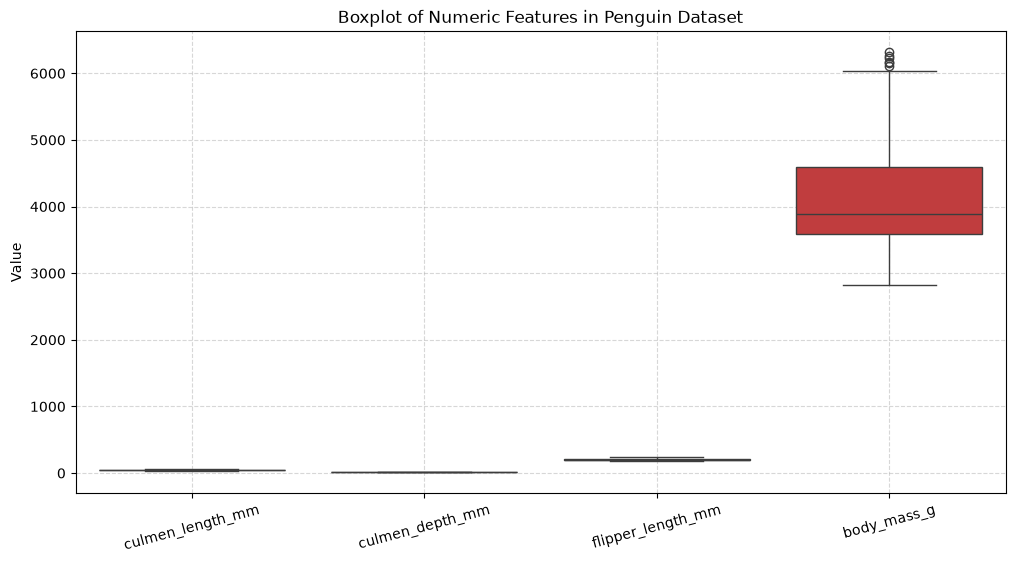

In [33]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[numeric_cols])
plt.title("Boxplot of Numeric Features in Penguin Dataset")
plt.ylabel("Value")
plt.xticks(rotation=15)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [34]:
for col in numeric_cols:
    s = df[col].dropna()
    q25, q75 = s.quantile(0.25), s.quantile(0.75)
    iqr = q75 - q25
    lower_bound = q25 - 1.5 * iqr
    upper_bound = q75 + 1.5 * iqr
    
    outliers = s[(s < lower_bound) | (s > upper_bound)]
    print(f"{col}: {len(outliers)} outliers: {outliers.tolist()}")

culmen_length_mm: 0 outliers: []
culmen_depth_mm: 0 outliers: []
flipper_length_mm: 0 outliers: []
body_mass_g: 6 outliers: [6148.0, 6114.0, 6258.0, 6176.0, 6317.0, 6237.0]



Due to the magnitude of `body_mass_g` (ranging from $\approx 2800\text{ g}$ to $>6000\text{ g}$), its box dominates the plot visual scale, while `culmen_length_mm`, `culmen_depth_mm`, and `flipper_length_mm` appear compressed at the bottom near zero.

 **`body_mass_g`:** **6 suspected outliers** detected above the upper threshold: `[6114.0, 6148.0, 6176.0, 6237.0, 6258.0, 6317.0]` grams.
 These 6 high body mass values represent unusually large adult male Gentoo penguins. While statistically flagged as outliers relative to the entire population, they represent natural biological variance rather than measurement errors or data corruption.

## A3. Handling Missing Data

In [35]:
df.isnull().sum()

species               0
island                0
culmen_length_mm     10
culmen_depth_mm      10
flipper_length_mm    10
body_mass_g          10
sex                  10
dtype: int64

In [38]:
missing_cols = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']

orig_stats = df[missing_cols].agg(['mean', 'std']).T
orig_stats.columns = ['Orig_Mean', 'Orig_Std']

# Constant Imputation
df_const = df[missing_cols].fillna(0)
const_stats = df_const.agg(['mean', 'std']).T
const_stats.columns = ['Const_Mean', 'Const_Std']

# Mean Imputation
df_mean = df[missing_cols].fillna(df[missing_cols].mean())
mean_stats = df_mean.agg(['mean', 'std']).T
mean_stats.columns = ['Mean_Imp_Mean', 'Mean_Imp_Std']

# KNN Predictive Imputation
knn_imputer = KNNImputer(n_neighbors=5)
df_knn = pd.DataFrame(knn_imputer.fit_transform(df[missing_cols]), columns=missing_cols)
knn_stats = df_knn.agg(['mean', 'std']).T
knn_stats.columns = ['KNN_Mean', 'KNN_Std']

comparison_df = pd.concat([orig_stats, const_stats, mean_stats, knn_stats], axis=1)
print(comparison_df.round(2))

                   Orig_Mean  Orig_Std  Const_Mean  Const_Std  Mean_Imp_Mean  \
culmen_length_mm       43.82      5.31       43.38       6.85          43.82   
culmen_depth_mm        17.34      1.78       17.16       2.47          17.34   
flipper_length_mm     199.22     13.17      197.23      23.77         199.22   
body_mass_g          4103.31    705.33     4062.28     812.02        4103.31   

                   Mean_Imp_Std  KNN_Mean  KNN_Std  
culmen_length_mm           5.28     43.81     5.29  
culmen_depth_mm            1.77     17.34     1.78  
flipper_length_mm         13.11    199.22    13.12  
body_mass_g              701.80   4102.99   703.59  
